In [9]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

from idxlab.clean import clean_ticker_data
from idxlab.config import load_config
from idxlab.data import DataLoader
from idxlab.evaluation import (
    bootstrap_auc_ci,
    evaluate_classifier,
    paired_bootstrap_auc_diff,
)
from idxlab.logging_setup import setup_logging
from idxlab.split import build_dataset, time_based_split
from idxlab.backtest import proba_to_signal, run_backtest
from idxlab.metrics import exposure_matched_return, summarize
from idxlab.error_analysis import (
    build_error_table, group_metrics, trend_regime, volatility_regime, worst_predictions,
)
from idxlab.walkforward import walk_forward_proba

Path("docs/results").mkdir(parents=True, exist_ok=True)
Path("docs/figures").mkdir(parents=True, exist_ok=True)

cfg = load_config()
setup_logging(cfg.log_level)
loader = DataLoader.from_config(cfg)
raw = loader.load_all()

ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent

14:25:19 | INFO     | idxlab.data | Cache hit for BBCA.JK (data\raw\BBCA_JK.parquet)
14:25:19 | INFO     | idxlab.data | Cache hit for BBRI.JK (data\raw\BBRI_JK.parquet)
14:25:19 | INFO     | idxlab.data | Cache hit for TLKM.JK (data\raw\TLKM_JK.parquet)
14:25:19 | INFO     | idxlab.data | Cache hit for ASII.JK (data\raw\ASII_JK.parquet)
14:25:19 | INFO     | idxlab.data | Cache hit for UNVR.JK (data\raw\UNVR_JK.parquet)


In [2]:
best = json.loads(Path("docs/results/day16_best_params.json").read_text(encoding="utf-8"))

# Order matters: simplest first. This is the challenge order in the protocol.
candidates = {
    "logreg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "rf_default": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
    "rf_tuned": RandomForestClassifier(**best["rf"]),
    "xgb_default": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=1,
    ),
    "xgb_tuned": XGBClassifier(**best["xgb"]),
}
dummy = DummyClassifier(strategy="most_frequent")  # reference only, not a candidate

chosen = "logreg"                 
model = candidates[chosen]

In [3]:
ohlcv = clean_ticker_data(raw["BBCA.JK"])
dataset = build_dataset(ohlcv)
split = time_based_split(dataset)
feature_cols = [c for c in dataset.columns if c not in ("forward_return", "direction")]
dev = pd.concat([split.train, split.val])            # test TIDAK dipakai
returns = ohlcv["Close"].pct_change()

PARAMS = dict(train_size=250, step=20, gap=1, rolling=True)      # sama dengan Day 22
proba_wf = walk_forward_proba(dev, model, feature_cols, **PARAMS)

In [4]:
# cek: satuan forward_return (persen) dan penyelarasan tanggal
assert np.allclose(dev["forward_return"] / 100, returns.shift(-1).loc[dev.index], atol=1e-9)

err = build_error_table(
    proba=proba_wf,
    y_true=dev.loc[proba_wf.index, "direction"],
    next_ret=dev.loc[proba_wf.index, "forward_return"] / 100,
)
assert err.index.isin(split.test.index).sum() == 0        # tidak ada hari test

print(len(err), "hari |", err.index.min().date(), "->", err.index.max().date())
print("akurasi            :", round(err["correct"].mean(), 3))
print("akurasi mayoritas  :", round(max(err["y_true"].mean(), 1 - err["y_true"].mean()), 3))
print("ROC-AUC            :", round(roc_auc_score(err["y_true"], err["proba"]), 3))

471 hari | 2024-02-19 -> 2026-02-12
akurasi            : 0.514
akurasi mayoritas  : 0.573
ROC-AUC            : 0.498


In [5]:
worst = worst_predictions(err, 10).join(dev[["rsi", "atr", "momentum"]])
worst["weekday"] = worst.index.day_name()
worst[["proba", "y_true", "next_ret", "loss", "rsi", "atr", "momentum", "weekday"]].round(3)

,proba,y_true,next_ret,loss,rsi,atr,momentum,weekday
date,,,,,,,,
2024-04-25,0.914,0,-0.015,2.448,51.347,204.009,2.625,Thursday
2025-04-10,0.104,1,0.006,2.260,46.922,342.928,2.146,Thursday
2024-04-19,0.894,0,-0.013,2.240,41.134,188.630,-5.955,Friday
2025-08-12,0.117,1,0.008,2.142,65.005,142.735,5.357,Tuesday
2024-08-19,0.118,1,0.005,2.136,59.332,137.527,5.063,Monday
2025-04-16,0.120,1,0.003,2.121,51.901,301.360,6.604,Wednesday
2024-04-18,0.878,0,0.000,2.102,41.134,189.059,-5.721,Thursday
2025-04-11,0.122,1,0.015,2.100,47.987,337.057,2.458,Friday
2025-04-14,0.127,1,0.021,2.063,50.652,323.139,3.385,Monday


In [6]:
size = pd.qcut(err["next_ret"].abs(), 5, labels=["smallest", "small", "medium", "large", "largest"])
by_size = group_metrics(err, size)
by_size[["n", "accuracy", "majority_acc", "edge", "acc_ci95", "strat_sum", "bench_sum"]].round(3)

,n,accuracy,majority_acc,edge,acc_ci95,strat_sum,bench_sum
smallest,95.0,0.537,0.684,-0.147,0.100,0.000,0.016
small,94.0,0.436,0.521,-0.085,0.100,-0.032,-0.005
medium,94.0,0.564,0.617,-0.053,0.100,-0.045,-0.231
large,94.0,0.479,0.574,-0.096,0.101,-0.147,-0.232
largest,94.0,0.553,0.532,0.021,0.101,0.184,0.267


In [7]:
close_dev = ohlcv["Close"].loc[:dev.index[-1]]                    
ret_dev = returns.loc[:dev.index[-1]]

trend = trend_regime(close_dev).reindex(err.index)       
vol = volatility_regime(ret_dev).reindex(err.index)
quarter = pd.Series(err.index.to_period("Q").astype(str), index=err.index)

tables = {
    "trend": group_metrics(err, trend),
    "volatility": group_metrics(err, vol),
    "quarter": group_metrics(err, quarter),
}
for name, t in tables.items():
    print(name)
    display(t[["n", "up_rate", "accuracy", "majority_acc", "edge", "acc_ci95", "auc", "signal_rate", "strat_sum", "bench_sum"]].round(3))

trend


,n,up_rate,accuracy,majority_acc,edge,acc_ci95,auc,signal_rate,strat_sum,bench_sum
above SMA200,206.0,0.432,0.481,0.568,-0.087,0.068,0.471,0.466,-0.050,-0.167
below SMA200,265.0,0.423,0.540,0.577,-0.038,0.060,0.526,0.204,0.012,-0.018


volatility


,n,up_rate,accuracy,majority_acc,edge,acc_ci95,auc,signal_rate,strat_sum,bench_sum
low vol,71.0,0.451,0.493,0.549,-0.056,0.116,0.482,0.282,-0.021,0.020
mid vol,176.0,0.403,0.483,0.597,-0.114,0.074,0.475,0.330,-0.114,-0.260
high vol,224.0,0.438,0.545,0.562,-0.018,0.065,0.522,0.321,0.096,0.055


quarter


,n,up_rate,accuracy,majority_acc,edge,acc_ci95,auc,signal_rate,strat_sum,bench_sum
2024Q1,27.0,0.407,0.407,0.593,-0.185,0.185,0.443,0.852,0.039,0.022
2024Q2,52.0,0.423,0.462,0.577,-0.115,0.135,0.479,0.462,-0.033,0.012
2024Q3,65.0,0.538,0.431,0.538,-0.108,0.120,0.514,0.215,0.001,0.071
2024Q4,62.0,0.403,0.500,0.597,-0.097,0.124,0.569,0.613,0.010,-0.052
2025Q1,58.0,0.328,0.655,0.672,-0.017,0.122,0.645,0.052,-0.008,-0.196
2025Q2,51.0,0.529,0.471,0.529,-0.059,0.137,0.440,0.314,0.042,0.119
2025Q3,64.0,0.406,0.562,0.594,-0.031,0.122,0.537,0.094,-0.033,-0.142
2025Q4,63.0,0.397,0.587,0.603,-0.016,0.122,0.563,0.175,-0.011,0.085
2026Q1,29.0,0.379,0.448,0.621,-0.172,0.181,0.571,0.517,-0.046,-0.103


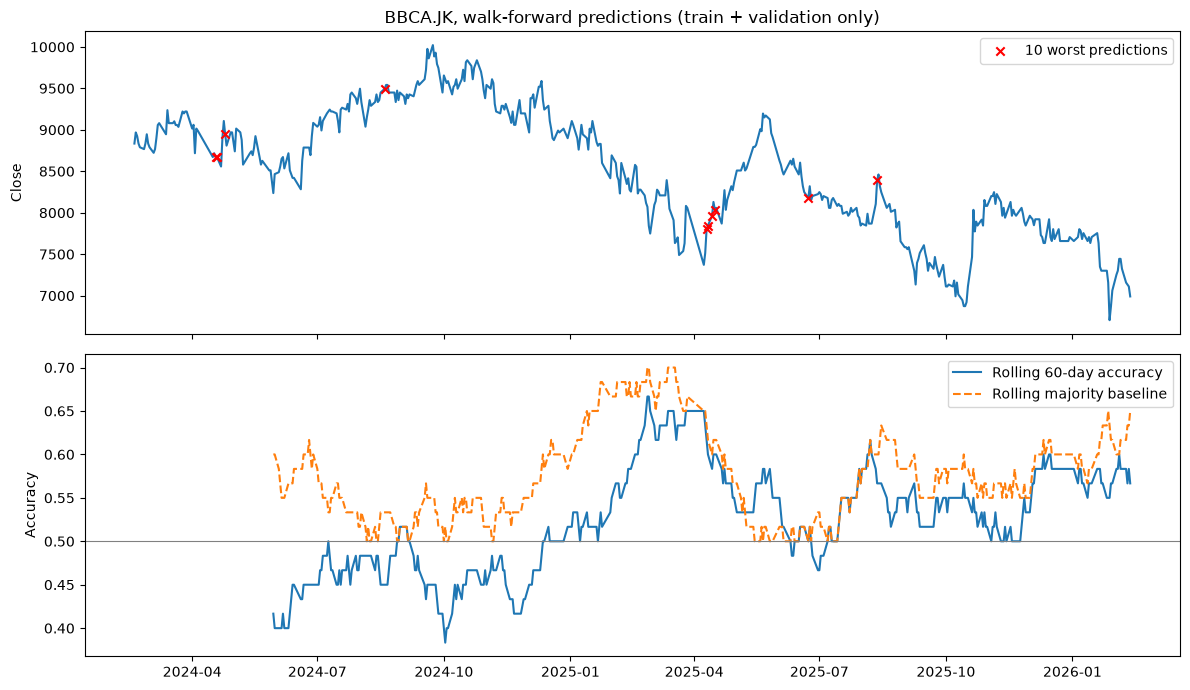

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

px = ohlcv["Close"].loc[err.index]
ax1.plot(px.index, px.values)
w10 = worst_predictions(err, 10)
ax1.scatter(w10.index, px.loc[w10.index], color="red", marker="x", zorder=3, label="10 worst predictions")
ax1.set_ylabel("Close")
ax1.set_title("BBCA.JK, walk-forward predictions (train + validation only)")
ax1.legend()

roll_acc = err["correct"].astype(float).rolling(60).mean()   
roll_major = err["y_true"].rolling(60).mean().pipe(lambda s: np.maximum(s, 1 - s))
ax2.plot(roll_acc.index, roll_acc, label="Rolling 60-day accuracy")
ax2.plot(roll_major.index, roll_major, linestyle="--", label="Rolling majority baseline")
ax2.axhline(0.5, color="grey", linewidth=0.8)
ax2.set_ylabel("Accuracy")
ax2.legend()

plt.tight_layout()
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "docs" / "figures" / "day23_error_analysis.png", dpi=150)
plt.show()

In [11]:
(ROOT / "docs" / "results").mkdir(parents=True, exist_ok=True)
worst.round(4).to_csv(ROOT / "docs" / "results" / "day23_worst_predictions.csv")
by_size.round(4).to_csv(ROOT / "docs" / "results" / "day23_by_move_size.csv")
for name, t in tables.items():
    t.round(4).to_csv(ROOT / "docs" / "results" / f"day23_by_{name}.csv")